In [305]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

In [306]:
columns = [f'A{i}' for i in range(1,17)]
df = pd.read_csv('crx.data', header=None, names=columns, na_values='?')

In [307]:
df.head()

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202.0,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43.0,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280.0,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100.0,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120.0,0,+


In [308]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A1      678 non-null    str    
 1   A2      678 non-null    float64
 2   A3      690 non-null    float64
 3   A4      684 non-null    str    
 4   A5      684 non-null    str    
 5   A6      681 non-null    str    
 6   A7      681 non-null    str    
 7   A8      690 non-null    float64
 8   A9      690 non-null    str    
 9   A10     690 non-null    str    
 10  A11     690 non-null    int64  
 11  A12     690 non-null    str    
 12  A13     690 non-null    str    
 13  A14     677 non-null    float64
 14  A15     690 non-null    int64  
 15  A16     690 non-null    str    
dtypes: float64(4), int64(2), str(10)
memory usage: 86.4 KB


In [309]:
df.isna().sum()

A1     12
A2     12
A3      0
A4      6
A5      6
A6      9
A7      9
A8      0
A9      0
A10     0
A11     0
A12     0
A13     0
A14    13
A15     0
A16     0
dtype: int64

In [310]:
# Проверяем количество полных дубликатов
df.duplicated().sum()

np.int64(0)

In [311]:
# Проверяем количество наблюдений каждого класса, включая возможные пропуски
# Построю график, чтоб увидеть возможный дисбаланс, на глаз он не большой
df['A16'].value_counts(dropna=False)

A16
-    383
+    307
Name: count, dtype: int64

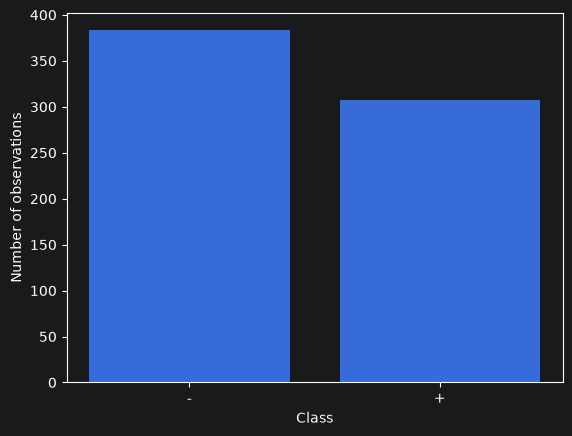

In [312]:
# Не наблюдаю прям сильного дисбаланса
# Думаю посмотреть на статистику фич, может быть там что то будет аномальное
class_counts = df['A16'].value_counts(dropna=False)
plt.bar(class_counts.index, class_counts.values)
plt.xlabel('Class')
plt.ylabel('Number of observations')
plt.show()

In [313]:
# Странно что A11 имеет медиану 0.0, а среднее 2.4, получается что минимум половина значений равна 0
# A15 имеет медиану 5.0, среднее 1017 и максимум 100000.0, признак длинного правого хвоста.
# Хочу посмотреть распределение А11 и А15, поэтому построю гистограмму
df.describe()

,A2,A3,A8,A11,A14,A15
count,678.000000,690.000000,690.000000,690.00000,677.000000,690.000000
mean,31.568171,4.758725,2.223406,2.40000,184.014771,1017.385507
std,11.957862,4.978163,3.346513,4.86294,173.806768,5210.102598
min,13.750000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,22.602500,1.000000,0.165000,0.00000,75.000000,0.000000
50%,28.460000,2.750000,1.000000,0.00000,160.000000,5.000000
75%,38.230000,7.207500,2.625000,3.00000,276.000000,395.500000
max,80.250000,28.000000,28.500000,67.00000,2000.000000,100000.000000


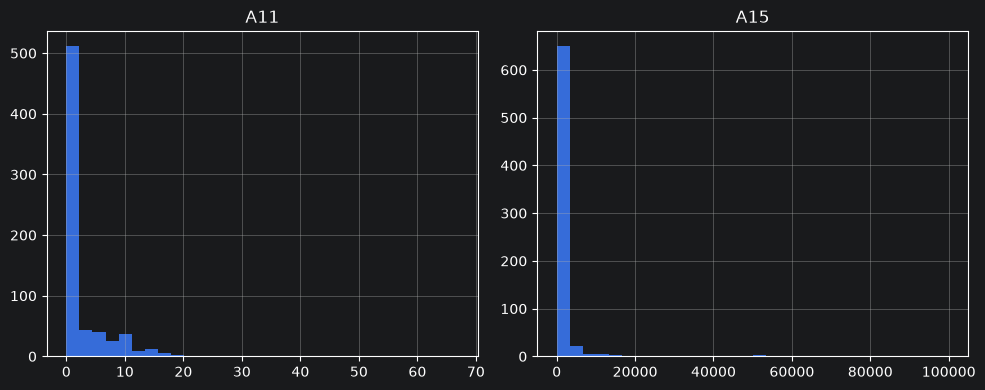

In [314]:
df[['A11', 'A15']].hist(bins=30, figsize=(10,4))
plt.tight_layout()
plt.show()

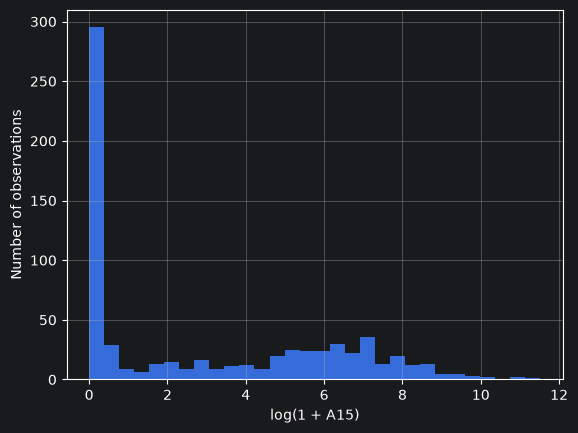

In [315]:
# Посмотрю A15 после логарифмического преобразования
np.log1p(df['A15']).hist(bins=30)
plt.xlabel('log(1 + A15)')
plt.ylabel('Number of observations')
plt.show()

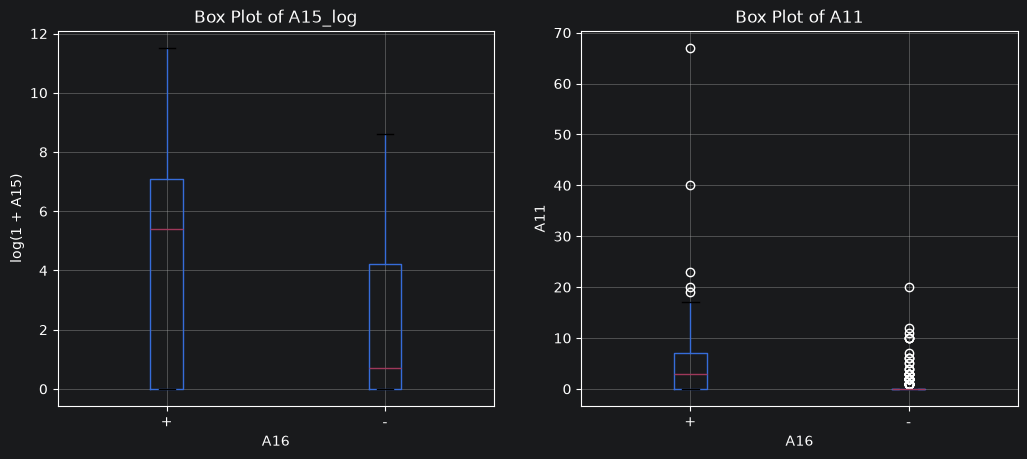

In [316]:
# Много нулевых значений наблюдаю, хочу проверить, отличается ли эта фича между классами + и -
# Для этого создам логарифмический признак А15, затем сравню его между целевыми классами
df['A15_log'] = np.log1p(df['A15'])
fig, ax = plt.subplots(1, 2, figsize=(12,5))

df.boxplot(column='A15_log', by='A16', ax=ax[0])
ax[0].set_ylabel('log(1 + A15)')
ax[0].set_title('Box Plot of A15_log')

df.boxplot(column='A11', by='A16', ax=ax[1])
ax[1].set_ylabel('A11')
ax[1].set_title('Box Plot of A11')

fig.suptitle('')
plt.show()

In [317]:
# У класса + медиана А11 около 3, а у минус она 0. У минуса даже сам ящик сжат до возле нуля.
# На основе этого сделаю вторую фичу, индикатор не нулевого А11
df['A11_positive'] = (df['A11'] > 0).astype(int)

In [318]:
# Теперь поделим данные, 60% train, 20% valid, 20% test
# x - фичи, y - истинный целевой класс
x = df.drop(columns='A16')
y = df['A16']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

In [319]:
# Заполним пропуски медианами train датой
numeric_cols = x_train.select_dtypes(include='number').columns
train_medians = x_train[numeric_cols].median()

x_train_filled = x_train.fillna(train_medians)
x_val_filled = x_val.fillna(train_medians)
x_test_filled = x_test.fillna(train_medians)

In [320]:
# Выбираем категориальные фичи и вычисляем моды только на train
categorical_cols = x_train.select_dtypes(exclude='number').columns
train_modes = x_train[categorical_cols].mode().iloc[0]

x_train_filled = x_train_filled.fillna(train_modes)
x_val_filled = x_val_filled.fillna(train_modes)
x_test_filled = x_test_filled.fillna(train_modes)

In [321]:
# Кодируем категориальные фичи
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cat_train_encoded = encoder.fit_transform(x_train_filled[categorical_cols])
cat_val_encoded = encoder.transform(x_val_filled[categorical_cols])
cat_test_encoded = encoder.transform(x_test_filled[categorical_cols])

In [322]:
# Объединяем числовые и закодированные категориальные фичи для дерева
x_train_tree = np.hstack((x_train_filled[numeric_cols], cat_train_encoded))
x_val_tree = np.hstack((x_val_filled[numeric_cols], cat_val_encoded))
x_test_tree = np.hstack((x_test_filled[numeric_cols], cat_test_encoded))

In [323]:
# Обучаем базовое дерево
# Видим что есть признаки переобучения, дерево идеально классифицирует на train дате, но на новых качество ниже.
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(x_train_tree, y_train)
y_val_pred = tree_model.predict(x_val_tree)
y_train_pred = tree_model.predict(x_train_tree)

# Accuracy
baseline_accuracy = accuracy_score(y_val, y_val_pred)

# F1 score
baseline_f1 = f1_score(y_val, y_val_pred, average='macro')

# Accuracy train
train_accuracy = accuracy_score(y_train, y_train_pred)

# F1 score train
train_f1 = f1_score(y_train, y_train_pred, average='macro')

print(f'{baseline_accuracy}, {baseline_f1}')
print(f'{train_accuracy}, {train_f1}')

0.8115942028985508, 0.8101587301587301
1.0, 1.0


In [324]:
# Подбираем гиперпараметр max_depth - глубина дерева
# Лучше себя показал параметр 1 и 3, выберу самое простое дерево - 1
depth_values = [1, 2, 3, 4, 5, 7, 10, None]
results = []

for depth in depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(x_train_tree, y_train)

    y_val_pred = model.predict(x_val_tree)
    y_train_pred = model.predict(x_train_tree)

    # F1 valid
    f1_val_pre = f1_score(y_val, y_val_pred, average='macro')

    # F1 train
    f1_train_pre = f1_score(y_train, y_train_pred, average='macro')

    results.append({'depth': depth, 'f1_score_valid': f1_val_pre, 'f1_score_train': f1_train_pre})

results_df = pd.DataFrame(results)
results_df

,depth,f1_score_valid,f1_score_train
0,1.0,0.833325,0.883787
1,2.0,0.826050,0.884015
2,3.0,0.833325,0.896033
3,4.0,0.795308,0.908369
4,5.0,0.797059,0.924889
5,7.0,0.825501,0.961024
6,10.0,0.810159,0.990238
7,NaN,0.810159,1.000000


In [325]:
# Обучаем дерево с параметром на макс. f1 по валидации
best_index = results_df['f1_score_valid'].idxmax()
best_depth = int(results_df.loc[best_index, 'depth'])

best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_tree.fit(x_train_tree, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [326]:
# Масштабируем дату для LogisticRegression и kNN
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_filled[numeric_cols])
x_val_scaled = scaler.transform(x_val_filled[numeric_cols])
x_test_scaled = scaler.transform(x_test_filled[numeric_cols])

In [327]:
# Теперь объединим с категориальными фичами
x_train_ready = np.hstack((x_train_scaled, cat_train_encoded))
x_val_ready = np.hstack((x_val_scaled, cat_val_encoded))
x_test_ready = np.hstack((x_test_scaled, cat_test_encoded))

In [328]:
# Обучаем логистик модельку, считаем accuracy и f1 score
log_model = LogisticRegression()
log_model.fit(x_train_ready, y_train)
log_val_pred = log_model.predict(x_val_ready)

# Accuracy logistic
log_accuracy = accuracy_score(y_val, log_val_pred)

# F1 score logistic
log_f1 = f1_score(y_val, log_val_pred, average='macro')

print(f'{log_accuracy}, {log_f1}')

0.855072463768116, 0.8549505991170906


In [329]:
# Обучаем kNN модельку, считаем accuracy и f1 score
knn_model = KNeighborsClassifier()
knn_model.fit(x_train_ready, y_train)
knn_val_pred = knn_model.predict(x_val_ready)

# Accuracy kNN
knn_accuracy = accuracy_score(y_val, knn_val_pred)

# F1 score kNN
knn_f1 = f1_score(y_val, knn_val_pred, average='macro')

print(f'{knn_accuracy}, {knn_f1}')

0.7971014492753623, 0.7907732293697206


In [330]:
# Подбираем число соседей по F1 macro на валидации
k_values = [1, 3, 5, 7, 9, 15, 21]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_ready, y_train)

    y_val_pred = model.predict(x_val_ready)
    y_train_pred = model.predict(x_train_ready)

    # f1 valid
    knn_f1_val = f1_score(y_val, y_val_pred, average='macro')

    # f1 train
    knn_f1_train = f1_score(y_train, y_train_pred, average='macro')

    results.append({'k': k, 'f1_val': knn_f1_val, 'f1_train': knn_f1_train})

knn_results_df = pd.DataFrame(results)
knn_results_df

,k,f1_val,f1_train
0,1,0.799710,1.000000
1,3,0.782724,0.903707
2,5,0.790773,0.891282
3,7,0.790773,0.865727
4,9,0.766421,0.860753
5,15,0.780146,0.840019
6,21,0.780146,0.837062


In [331]:
# Выбираем параметр с макс. f1 по валидации, затем обучаем
best_index = knn_results_df['f1_val'].idxmax()
best_k = knn_results_df.loc[best_index, 'k']

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(x_train_ready, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",np.int64(1)
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['+','-']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [332]:
# Теперь подбираем для логистической регрессии
C_values = [0.01, 0.1, 1, 10, 100]
results = []
for C in C_values:
    logistic_model = LogisticRegression(C=C)

    logistic_model.fit(x_train_ready, y_train)

    logistic_val_pred = logistic_model.predict(x_val_ready)

    # F1
    logistic_f1 = f1_score(y_val, logistic_val_pred, average='macro')

    results.append({'C': C, 'f1_score': logistic_f1})

log_results_df = pd.DataFrame(results)
log_results_df

,C,f1_score
0,0.01,0.802249
1,0.10,0.840042
2,1.00,0.854951
3,10.00,0.840446
4,100.00,0.833114


In [333]:
# Выбираем C по максимальному F1 macro на валидации
best_index = log_results_df['f1_score'].idxmax()
best_C = log_results_df.loc[best_index, 'C']

best_log = LogisticRegression(C=best_C)
best_log.fit(x_train_ready, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",np.float64(1.0)
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider t

In [334]:
# Вычисляем accuracy и f1 score для каждой модели по лучшему параметру
best_tree_predict = best_tree.predict(x_test_tree)
best_knn_predict = best_knn.predict(x_test_ready)
best_log_predict = best_log.predict(x_test_ready)

# Accuracy
best_tree_accuracy = accuracy_score(y_test, best_tree_predict)
best_knn_accuracy = accuracy_score(y_test, best_knn_predict)
best_log_accuracy = accuracy_score(y_test, best_log_predict)

# F1 score
best_tree_f1 = f1_score(y_test, best_tree_predict, average='macro')
best_knn_f1 = f1_score(y_test, best_knn_predict, average='macro')
best_log_f1 = f1_score(y_test, best_log_predict, average='macro')

In [335]:
# Сравниваем выбранные модели на тестовой выборке
comparison = pd.DataFrame({
    'Model': ['DecisionTree', 'kNN', 'LogisticRegression'],
    'Accuracy': [best_tree_accuracy, best_knn_accuracy, best_log_accuracy],
    'F1 macro': [best_tree_f1, best_knn_f1, best_log_f1]
})

comparison

,Model,Accuracy,F1 macro
0,DecisionTree,0.789855,0.789756
1,kNN,0.768116,0.762069
2,LogisticRegression,0.818841,0.818067


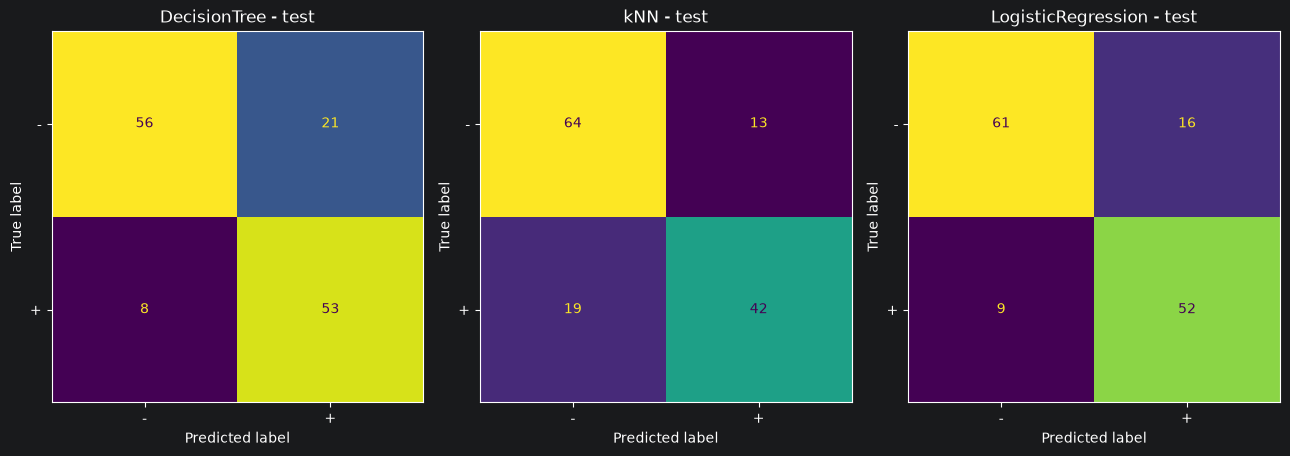

In [336]:
# Строим матрицы ошибок трёх моделей на тестовой выборке
labels = ['-', '+']
fig, ax = plt.subplots(1, 3, figsize=(13, 6))

disp_tree = ConfusionMatrixDisplay(confusion_matrix(y_test, best_tree_predict, labels=labels), display_labels=labels)
disp_tree.plot(ax=ax[0], colorbar=False)
disp_knn = ConfusionMatrixDisplay(confusion_matrix(y_test, best_knn_predict, labels=labels), display_labels=labels)
disp_knn.plot(ax=ax[1], colorbar=False)
disp_log = ConfusionMatrixDisplay(confusion_matrix(y_test, best_log_predict, labels=labels), display_labels=labels)
disp_log.plot(ax=ax[2], colorbar=False)

ax[0].set_title('DecisionTree - test')
ax[1].set_title('kNN - test')
ax[2].set_title('LogisticRegression - test')
plt.tight_layout()
plt.show()

In [337]:
# Получаем вероятности
tree_proba = best_tree.predict_proba(x_test_tree)
knn_proba = best_knn.predict_proba(x_test_ready)
log_proba = best_log.predict_proba(x_test_ready)

In [338]:
# Считаем класс + положительным
y_test_binary = (y_test == '+')

fpr_tree, tpr_tree, _ = roc_curve(y_test_binary, tree_proba[:, 0])
auc_tree = auc(fpr_tree, tpr_tree)

fpr_knn, tpr_knn, _ = roc_curve(y_test_binary, knn_proba[:, 0])
auc_knn = auc(fpr_knn, tpr_knn)

fpr_log, tpr_log, _ = roc_curve(y_test_binary, log_proba[:, 0])
auc_log = auc(fpr_log, tpr_log)

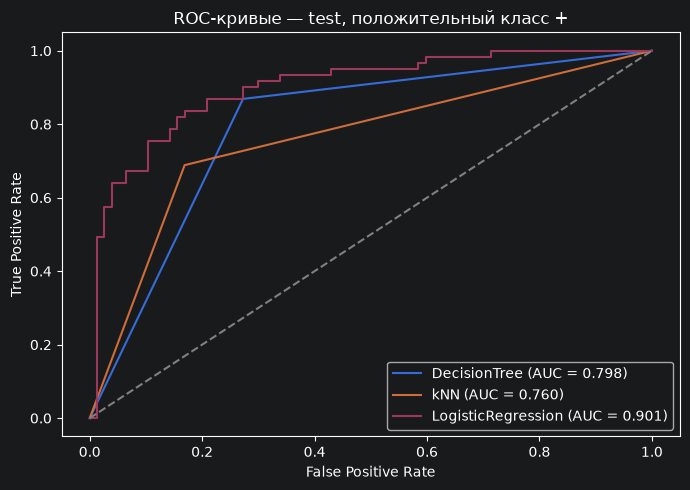

In [339]:
# Сравниваем ROC кривые моделей на тесте
plt.figure(figsize=(7, 5))

plt.plot(fpr_tree, tpr_tree, label=f'DecisionTree (AUC = {auc_tree:.3f})')
plt.plot(fpr_knn, tpr_knn, label=f'kNN (AUC = {auc_knn:.3f})')
plt.plot(fpr_log, tpr_log, label=f'LogisticRegression (AUC = {auc_log:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые — test, положительный класс +')
plt.legend()
plt.tight_layout()
plt.show()

На тестовой выборке наибольшую ROC-AUC показала логистическая регрессия - 0,901, затем дерево решений - 0,798 и kNN - 0,760. Среди рассмотренных моделей логистическая регрессия лучше ранжирует объекты положительного класса + относительно отрицательного. Все модели превосходят случайное ранжирование.

Итоговое заключение

После подготовки данных и подбора параметров сравнены дерево решений, kNN и логистическая регрессия. На данном тестовом разбиении лучший результат показала LogisticRegression: accuracy = 0,819, F1 macro = 0,818, ROC-AUC = 0,901. Ограничение глубины дерева уменьшило переобучение и улучшило валидационный F1 macro относительно базового дерева.